# Functions in Python

A **function** is a named block of code that does one task. You define it once and call it many times. Functions make programs shorter, easier to test and easier to change.

**After this lesson you can:**

1. Define functions with parameters, default values and return values.
2. Use positional, keyword, `*args` and `**kwargs` arguments.
3. Explain local and global scope.
4. Write a docstring and test a function.

## 1. Define and Call a Function

```python
def name(parameter_1, parameter_2=default):
    """Docstring: what the function does."""
    ...
    return result
```

- **Parameters** are the names in the definition. **Arguments** are the values in the call.
- `return` sends a value back. A function without `return` returns `None`.

In [1]:
def bmi(weight_kg: float, height_m: float) -> float:
    """Return the body-mass index: weight divided by height squared."""
    return weight_kg / height_m ** 2

def bmi_category(value: float) -> str:
    """Classify a BMI value with the WHO cut-offs."""
    if value < 18.5:
        return "underweight"
    if value < 25:
        return "normal"
    if value < 30:
        return "overweight"
    return "obese"

for w, h in [(55, 1.70), (72, 1.78), (95, 1.75)]:
    v = bmi(w, h)
    print(f"{w} kg, {h} m -> BMI {v:.1f} ({bmi_category(v)})")

help(bmi)

55 kg, 1.7 m -> BMI 19.0 (normal)
72 kg, 1.78 m -> BMI 22.7 (normal)
95 kg, 1.75 m -> BMI 31.0 (obese)
Help on function bmi in module __main__:

bmi(weight_kg: float, height_m: float) -> float
    Return the body-mass index: weight divided by height squared.



## 2. Kinds of Arguments

| Kind | Example definition | Example call |
| :--- | :--- | :--- |
| positional | `def f(a, b)` | `f(1, 2)` |
| keyword | `def f(a, b)` | `f(b=2, a=1)` |
| default value | `def f(a, b=10)` | `f(1)` |
| variable positional | `def f(*args)` | `f(1, 2, 3)` → `args = (1, 2, 3)` |
| variable keyword | `def f(**kwargs)` | `f(x=1)` → `kwargs = {"x": 1}` |
| keyword-only | `def f(a, *, verbose=False)` | `f(1, verbose=True)` |

In [2]:
def describe(name, *scores, unit="points", **extra):
    avg = sum(scores) / len(scores) if scores else 0
    text = f"{name}: {len(scores)} scores, average {avg:.1f} {unit}"
    if extra:
        text += " | " + ", ".join(f"{k}={v}" for k, v in extra.items())
    return text

print(describe("Ali", 70, 85, 90))
print(describe("Zeynep", 88, 92, unit="%", school="ODTÜ", year=2))
print(describe("Can"))

numbers = [3, 9, 4]
print("unpacking a list into arguments:", describe("Ece", *numbers))

Ali: 3 scores, average 81.7 points
Zeynep: 2 scores, average 90.0 % | school=ODTÜ, year=2
Can: 0 scores, average 0.0 points
unpacking a list into arguments: Ece: 3 scores, average 5.3 points


## 3. Scope: Local and Global Names

A name that you assign inside a function is **local**: it exists only while the function runs. A function can read a **global** name, but an assignment inside the function creates a new local name. Python looks up names in the order **L**ocal → **E**nclosing → **G**lobal → **B**uilt-in (the LEGB rule).

In [3]:
counter = 0

def increment_wrong():
    counter = 1          # a NEW local variable; the global one does not change
    return counter

def increment_pure(value):
    return value + 1     # better: take input, return output

increment_wrong()
print("global counter after increment_wrong():", counter)
counter = increment_pure(counter)
print("global counter after increment_pure()  :", counter)

def make_multiplier(factor):
    def multiply(x):     # 'factor' comes from the enclosing scope (a closure)
        return x * factor
    return multiply

double, triple = make_multiplier(2), make_multiplier(3)
print("closures:", double(5), triple(5))

global counter after increment_wrong(): 0
global counter after increment_pure()  : 1
closures: 10 15


A **pure function** uses only its arguments and returns a result; it does not change global state. Pure functions are easy to test and to reuse. The closure `make_multiplier` returns a new function that remembers `factor`.

## 4. Test a Function

A simple test calls the function with known inputs and checks the output with `assert`. M02 shows how to organise many tests with **pytest**.

In [4]:
assert round(bmi(72, 1.78), 1) == 22.7
assert bmi_category(18.4) == "underweight"
assert bmi_category(24.99) == "normal"
assert bmi_category(30) == "obese"
print("all tests passed")

all tests passed


## 5. Visualise a Function

A function maps inputs to outputs. The plot evaluates `bmi_category()` on a grid of weights and heights and colours each point by the result.

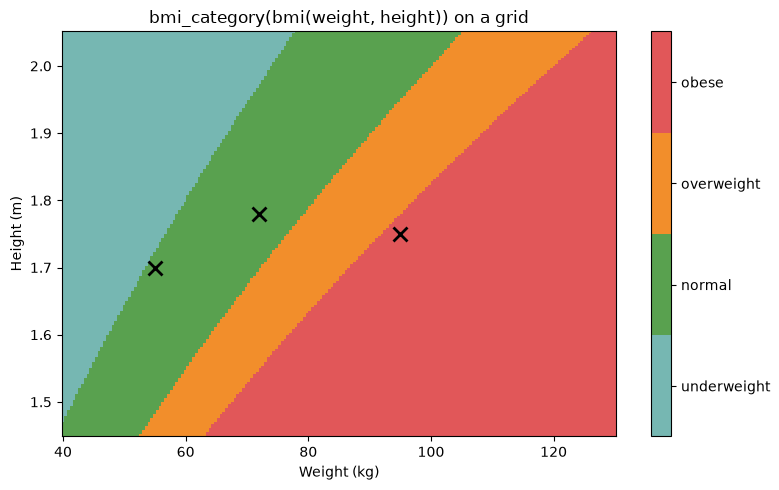

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

weights = np.linspace(40, 130, 200)
heights = np.linspace(1.45, 2.05, 200)
cats = ["underweight", "normal", "overweight", "obese"]
grid = np.array([[cats.index(bmi_category(bmi(w, h))) for w in weights] for h in heights])

fig, ax = plt.subplots(figsize=(8, 5))
cmap = ListedColormap(["#76B7B2", "#59A14F", "#F28E2B", "#E15759"])
mesh = ax.pcolormesh(weights, heights, grid, cmap=cmap, shading="auto")
cbar = fig.colorbar(mesh, ticks=[0.375, 1.125, 1.875, 2.625])
cbar.ax.set_yticklabels(cats)
for w, h in [(55, 1.70), (72, 1.78), (95, 1.75)]:
    ax.plot(w, h, "kx", ms=10, mew=2)
ax.set(title="bmi_category(bmi(weight, height)) on a grid", xlabel="Weight (kg)", ylabel="Height (m)")
plt.tight_layout()
plt.show()

*Insight: A good function does one task, has a clear name, takes its inputs as parameters and returns its result. If you cannot describe a function in one sentence, split it into smaller functions.*

## Real-World Use Case or Analogy

A function is like a **recipe card** in a restaurant kitchen. The card has a name ("Tomato soup"), a list of ingredients (parameters) and the steps. Any cook can use the card, and the result is the same every time. When the chef improves the recipe, only the card changes; every dish that uses it improves.

In data teams, functions turn notebook code into reusable building blocks: `load_data()`, `clean()`, `train()`, `evaluate()`. These functions later move into a package (Lesson 07) and get automated tests (M02).